# 第5回　特徴学習と事前学習済み表現

「ラベルなしで，使い回せる表現をどう学習するか」を，小さな人工データと NumPy で確かめる．

| 節 | テーマ |
|---|---|
| §1 | 埋め込み空間と類似検索 |
| §2 | オートエンコーダと PCA |
| §3 | 対照学習：拡張が不変性を決める |
| §4 | マスク予測 |
| §5 | CLIP 風の画像・テキスト対照学習とゼロショット分類 |
| §6 | （任意）PyTorch で対照損失を書く |

```{admonition} この章の使い方
:class: tip
ページ右上のロケットのボタンから Colab で開くか，[環境構築](setup.md) に従って手元で実行する．セルは **上から順に** 実行する．
**やってみよう** は `# TODO` の行を書き換えて再実行する（先に結果を予想してから）．「補助コード」と書いたセルは本題ではない補助の実装で，中身は読まなくてよい（折りたたんである）．
詳しくは [ノートブックの使い方](usage.md)．
```

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')        # 小さな行列の計算では並列化が逆に遅くなるので 1 コアで計算する
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')   # （numpy を読み込む前に設定する必要がある）
os.environ.setdefault('MKL_NUM_THREADS', '1')
import numpy as np
import matplotlib.pyplot as plt
try:
    import matplotlib_fontja                       # 図の日本語フォント（pip install matplotlib-fontja）
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=False)
    import matplotlib_fontja
np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(0)

def softmax_rows(U):
    U = U - U.max(axis=1, keepdims=True)
    E = np.exp(U)
    return E / E.sum(axis=1, keepdims=True)

## §1 埋め込み空間と類似検索

埋め込み＝入力をベクトル空間の点として表したもの．良い埋め込みでは「意味が近い」＝「ベクトルが近い」．
近さはコサイン類似度で測る：

$$\cos(\boldsymbol{a},\boldsymbol{b}) = \frac{\boldsymbol{a}^\top\boldsymbol{b}}{\|\boldsymbol{a}\|\,\|\boldsymbol{b}\|}$$

In [2]:
def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

print("cos((1,0),(1,1)) =", cosine(np.array([1.0, 0.0]), np.array([1.0, 1.0])))   #講義のクイズ：1/√2 ≈ 0.71

# 画像の埋め込み（学習済みモデルの出力のつもりで，手で作った 3 次元ベクトル）
names = ['柴犬', '秋田犬', 'プードル', '三毛猫', '黒猫', '軽トラック', 'バス']
# 3 つの成分は，おおよそ（犬らしさ，猫らしさ，乗り物らしさ）のつもり
E = np.array([[0.9, 0.2, 0.0], [0.8, 0.3, 0.1], [0.7, 0.4, 0.0],
              [0.3, 0.9, 0.0], [0.2, 0.8, 0.1],
              [0.0, 0.1, 0.9], [0.1, 0.0, 0.8]])

def search(query, E, k=3):
    En = E / np.linalg.norm(E, axis=1, keepdims=True)       # 正規化しておけば内積＝コサイン類似度
    sims = En @ (query / np.linalg.norm(query))
    order = np.argsort(-sims)[:k]                           # 類似度の大きい順に，上位 k 個の番号
    return [(names[i], round(float(sims[i]), 3)) for i in order]

print("クエリ＝柴犬の埋め込み →", search(E[0], E))
print("クエリ＝黒猫の埋め込み →", search(E[4], E))

cos((1,0),(1,1)) = 0.7071067811865475
クエリ＝柴犬の埋め込み → [('柴犬', 1.0), ('秋田犬', 0.983), ('プードル', 0.955)]
クエリ＝黒猫の埋め込み → [('黒猫', 1.0), ('三毛猫', 0.99), ('プードル', 0.687)]


**読み取り**　検索にはラベルも追加学習も要らない．埋め込みを計算して，近いものを並べるだけ．

**やってみよう 1-1**　「猫と犬の中間」のクエリ `(0.5, 0.5, 0)` では何が上位に来るか．「乗り物」に近いクエリを自分で作って検索する．

In [3]:
print(search(np.array([0.5, 0.5, 0.0]), E))      # TODO: クエリを変える
print(search(np.array([0.0, 0.0, 1.0]), E))

[('プードル', 0.965), ('秋田犬', 0.904), ('三毛猫', 0.894)]
[('軽トラック', 0.994), ('バス', 0.992), ('黒猫', 0.12)]


## §2 オートエンコーダと PCA

オートエンコーダ：符号化器で入力を低次元の $\boldsymbol{z}$ に圧縮し，復号器で元に戻す．教師信号は**入力そのもの**．

$$\boldsymbol{z} = W_e\boldsymbol{x},\qquad \tilde{\boldsymbol{x}} = W_d\boldsymbol{z},\qquad L = \frac{1}{N}\sum_n \|\boldsymbol{x}_n - \tilde{\boldsymbol{x}}_n\|^2$$

データ：10 次元だが，実質 2 次元の構造（＋小さなノイズ）を持つ 500 点．ボトルネックを 2 次元にすると，その構造だけが $\boldsymbol{z}$ に残る．
符号化器・復号器が線形なら，PCA（主成分分析：データのばらつきが大きい方向だけを残す圧縮法）と同じ圧縮になることも確かめる．
コードではデータを 1 行に 1 件ずつ並べるので，式の $W_e\boldsymbol{x}$ は `X @ We` と右から掛ける形になる．

再構成誤差：オートエンコーダ 0.0803 / PCA 0.0803
部分空間の一致度（1 に近いほど同じ）= [1. 1.]


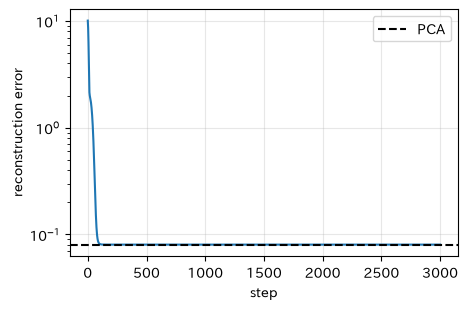

In [4]:
N, D, d_true = 500, 10, 2
basis = np.linalg.qr(rng.normal(size=(D, d_true)))[0]                # 10 次元の中の 2 次元部分空間
latent = rng.normal(size=(N, d_true)) * [3.0, 1.5]                   # 本当の 2 次元の座標（ばらつき 3 と 1.5）
X = latent @ basis.T                                                 # 10 次元の空間に置く
X = X + 0.1 * rng.normal(size=(N, D))                                # 小さなノイズを足す
X = X - X.mean(axis=0)                                               # 中心化

def train_autoencoder(X, d_z, lr=0.01, steps=3000, seed=0):
    r = np.random.default_rng(seed)
    We = r.normal(size=(X.shape[1], d_z)) * 0.1                      # 符号化器（1 行が 1 件のデータ：z = x We．式の W_e の転置に当たる）
    Wd = r.normal(size=(d_z, X.shape[1])) * 0.1                      # 復号器（x~ = z Wd）
    hist = []
    for t in range(steps):
        Zc = X @ We
        R = Zc @ Wd - X                                              # 再構成誤差
        gWd = Zc.T @ R * 2 / len(X)
        gWe = X.T @ (R @ Wd.T) * 2 / len(X)
        We -= lr * gWe; Wd -= lr * gWd
        hist.append(np.mean(np.sum(R ** 2, axis=1)))
    return We, Wd, np.array(hist)

We, Wd, hist = train_autoencoder(X, d_z=2)

# PCA（特異値分解）で 2 次元に落として戻したときの誤差
U, S, Vt = np.linalg.svd(X, full_matrices=False)
X_pca = X @ Vt[:2].T @ Vt[:2]
err_pca = np.mean(np.sum((X - X_pca) ** 2, axis=1))
print(f"再構成誤差：オートエンコーダ {hist[-1]:.4f} / PCA {err_pca:.4f}")

# オートエンコーダが残した 2 次元の平面と，PCA が残した平面が同じかを調べる（補助コード．数値だけ見ればよい）．
# 出力は 2 つの平面のなす角の cos．両方 1 なら同じ平面．
Q = np.linalg.qr(Wd.T)[0]
print("部分空間の一致度（1 に近いほど同じ）=", np.linalg.svd(Q.T @ Vt[:2].T, compute_uv=False))

plt.figure(figsize=(5, 3.2)); plt.semilogy(hist); plt.axhline(err_pca, ls='--', c='k', label='PCA')
plt.xlabel('step'); plt.ylabel('reconstruction error'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**やってみよう 2-1**　ボトルネックの次元 `d_z` を 1, 2, 5 に変えると再構成誤差はどうなるか．「2 で十分」な理由を考える．

In [5]:
for d_z in (1, 2, 5):                                   # TODO
    _, _, h = train_autoencoder(X, d_z=d_z)
    print(f"d_z={d_z}: 再構成誤差 {h[-1]:.4f}")
# 解答：1 では情報が足りず誤差が大きい．2 でデータの構造を取り切り，5 に増やしても減るのはノイズ分だけ．

d_z=1: 再構成誤差 2.2135
d_z=2: 再構成誤差 0.0803
d_z=5: 再構成誤差 0.0735


## §3 対照学習：拡張が不変性を決める

**設定**　1 枚の「画像」は 10 次元ベクトルで，中身は次の 2 つが混ざっている（混ぜ方は固定の回転行列）．

- **内容**（2 次元）：何が写っているか．4 種類の物体（4 つのクラスタ）．
- **見え方**（8 次元）：明るさ・背景・位置など．値のばらつきが大きく，内容とは無関係．

**データ拡張**＝同じ内容のまま，見え方だけを取り替えた 2 枚（正例対）を作る．
対照学習は「同じ元画像からの 2 枚は近く，別の画像とは遠く」を損失にする（InfoNCE）．

$$L = -\frac{1}{N}\sum_i \log \frac{\exp(s_{ii}/\tau)}{\sum_j \exp(s_{ij}/\tau)},\qquad s_{ij} = \cos(\boldsymbol{z}^a_i, \boldsymbol{z}^b_j)$$

これは「$i$ 番目の画像の相手は $N$ 枚のうちどれか」という $N$ クラス分類の交差エントロピー（第2回と同じ形）．**クラスのラベルは使わない．**
この損失は InfoNCE と呼ばれる．コードでは，逆向き（b から a を当てる）も計算して 2 つを平均し，温度は $\tau=0.2$ とする．

- 内容と見え方を回転行列で混ぜるのは，「どの成分が内容か」を見ただけでは分からなくするため（本物の画像でも，犬らしさは特定の画素に書かれていない）．
- 表現の良さは **1-最近傍** で測る：ラベル付きの参照 40 枚のうち，埋め込みが最も近い 1 枚のラベルを答える（の類似検索で分類する）．
  学習が要らないので，ここでは第4回の線形プローブの代わりに使う．

1-最近傍の正解率：生の入力 0.545 → 対照学習後の埋め込み 0.983


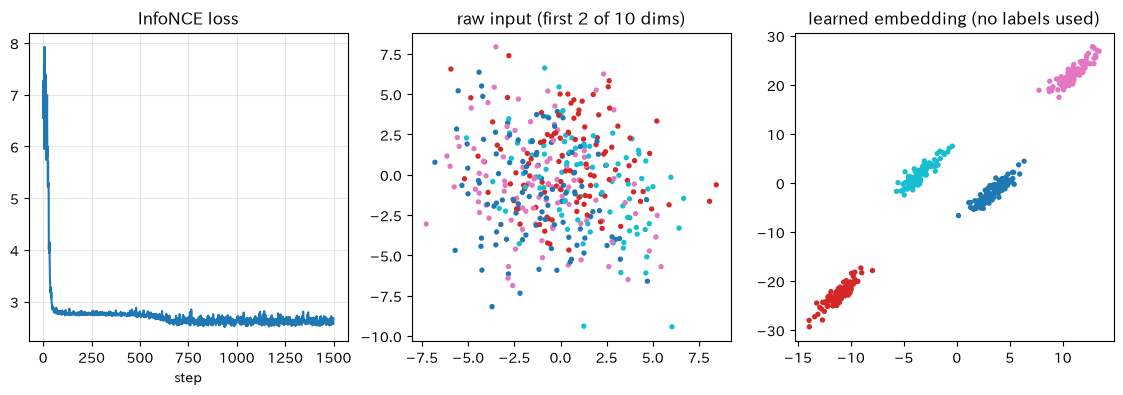

In [6]:
D_C, D_N = 2, 8
Qmix = np.linalg.qr(np.random.default_rng(1).normal(size=(D_C + D_N, D_C + D_N)))[0]   # 内容と見え方を混ぜる固定の回転
CENTERS = np.array([[2, 2], [2, -2], [-2, 2], [-2, -2]], dtype=float)

def sample_content(n, r):
    k = r.integers(0, 4, size=n)                         # クラスタ番号（評価にだけ使う．学習では使わない）
    return CENTERS[k] + 0.3 * r.normal(size=(n, 2)), k

def render(content, r, nuisance_std=3.0):
    # 内容に「見え方」を付けて 1 枚の画像（10 次元）にする
    nuis = nuisance_std * r.normal(size=(len(content), D_N))
    return np.concatenate([content, nuis], axis=1) @ Qmix.T

def augment_pair(content, r, break_dim=None):
    # 同じ内容から，見え方だけが違う 2 枚を作る．break_dim を指定すると，その内容の次元も壊す（やってみよう 3-1）
    ca, cb = content.copy(), content.copy()
    if break_dim is not None:
        ca[:, break_dim] = 2.0 * r.normal(size=len(content))
        cb[:, break_dim] = 2.0 * r.normal(size=len(content))
    return render(ca, r), render(cb, r)

def normalize(U):
    n = np.linalg.norm(U, axis=1, keepdims=True) + 1e-12
    return U / n, n

def info_nce(Za, Zb, tau=0.2):
    # Za, Zb：正規化済みの埋め込み（N×d）．i 行目どうしが正例対．
    # 戻り値：(損失, Za についての勾配, Zb についての勾配, 類似度行列)
    # 読むのは 3 行：S（類似度行列）→ Pr（各行を N クラス分類の確率に）→ loss（対角の −log）．残りは勾配計算．
    N = len(Za)
    S = Za @ Zb.T / tau                                  # 類似度行列（N×N）
    I = np.eye(N)
    Pr, Pc = softmax_rows(S), softmax_rows(S.T).T        # Pr：a から相手の b を当てる確率．Pc：b から相手の a を当てる確率
    loss = -(np.log(np.diag(Pr) + 1e-12).mean() + np.log(np.diag(Pc) + 1e-12).mean()) / 2
    dS = ((Pr - I) + (Pc - I)) / (2 * N) / tau           # 「予測 − 正解」の形
    return loss, dS @ Zb, dS.T @ Za, S

# 補助コード：対照学習の訓練ループ（「2 枚作る → 埋め込む → 損失 → 勾配で W を更新」の繰り返し．勾配の式は追わなくてよい）
def train_contrastive(steps=1500, batch=64, d_out=2, lr=0.5, break_dim=None, seed=0):
    r = np.random.default_rng(seed)
    W = r.normal(size=(D_C + D_N, d_out)) * 0.1          # 線形の符号化器 u = x W
    hist = []
    for t in range(steps):
        content, _ = sample_content(batch, r)
        Xa, Xb = augment_pair(content, r, break_dim)
        (Za, na), (Zb, nb) = normalize(Xa @ W), normalize(Xb @ W)
        loss, gZa, gZb, _ = info_nce(Za, Zb)
        # 正規化の逆伝播：z = u/|u| → du = (dz − z (z·dz)) / |u|
        gUa = (gZa - Za * np.sum(Za * gZa, axis=1, keepdims=True)) / na
        gUb = (gZb - Zb * np.sum(Zb * gZb, axis=1, keepdims=True)) / nb
        W -= lr * (Xa.T @ gUa + Xb.T @ gUb)
        hist.append(loss)
    return W, np.array(hist)

def knn_accuracy(encode, n_ref=40, n_test=400, seed=99):
    # 表現の良さを 1-最近傍で測る：ラベル付きの参照 40 枚のうち最も近いもののラベルを答える
    r = np.random.default_rng(seed)
    c_ref, k_ref = sample_content(n_ref, r); c_te, k_te = sample_content(n_test, r)
    Zr, _ = normalize(encode(render(c_ref, r))); Zt, _ = normalize(encode(render(c_te, r)))
    nearest = (Zt @ Zr.T).argmax(axis=1)                 # 各テスト画像に最も似た参照画像の番号
    return float(np.mean(k_ref[nearest] == k_te))        # その参照画像のラベルが，正しいラベルと一致する割合

W, hist = train_contrastive()

def encode_raw(X):          # 何もしない（生の入力をそのまま使う）
    return X

def encode_learned(X):      # 学習した符号化器で埋め込む
    return X @ W

print(f"1-最近傍の正解率：生の入力 {knn_accuracy(encode_raw):.3f} → 対照学習後の埋め込み {knn_accuracy(encode_learned):.3f}")

r = np.random.default_rng(5); c, k = sample_content(400, r); Ximg = render(c, r)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(hist); ax[0].set_title('InfoNCE loss'); ax[0].set_xlabel('step'); ax[0].grid(alpha=0.3)
ax[1].scatter(Ximg[:, 0], Ximg[:, 1], c=k, s=8, cmap='tab10'); ax[1].set_title('raw input (first 2 of 10 dims)')
Zp = Ximg @ W
ax[2].scatter(Zp[:, 0], Zp[:, 1], c=k, s=8, cmap='tab10'); ax[2].set_title('learned embedding (no labels used)')
plt.show()

**図の見方**　中央：生の入力の最初の 2 成分．色（＝物体の種類）が混ざっている．右：学習した埋め込み．同じ色が固まっていれば，ラベルなしで内容を取り出せたことになる．

**読み取り**　生の入力では「見え方」のばらつきが大きく，近い画像を探しても同じ物体にならない．
対照学習は，拡張で変わる成分（見え方）を捨て，変わらない成分（内容）だけを残す符号化器を，**ラベルなし**で学習した．色分けは評価のために後から付けたもの．

**やってみよう 3-1（やってはいけない拡張）**　拡張が**内容の一部まで壊す**とどうなるか．
`break_dim=1` は「内容の 2 番目の次元（上下の違い）も拡張で変わってしまう」設定．傷検査で「傷が消えるほど強い切り抜き」をするのに相当する．
**先に予想を書く**：1-最近傍の正解率は（上がる／変わらない／下がる）．理由も 1 行で．

1-最近傍の正解率：内容を壊す拡張で学習 0.477


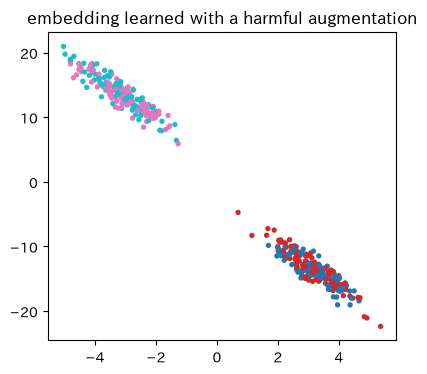

In [7]:
W_bad, _ = train_contrastive(break_dim=1)                 # TODO: break_dim=0 でも試す
def encode_bad(X):
    return X @ W_bad

print(f"1-最近傍の正解率：内容を壊す拡張で学習 {knn_accuracy(encode_bad):.3f}")
Zb_ = Ximg @ W_bad
plt.figure(figsize=(4.5, 4)); plt.scatter(Zb_[:, 0], Zb_[:, 1], c=k, s=8, cmap='tab10')
plt.title('embedding learned with a harmful augmentation'); plt.show()
# 解答：正解率は 0.5 前後に落ちる．拡張で変わる次元は「同じとみなせ」と教えたことになり，
#       その次元で区別していた 2 組のクラスタが重なってしまう．拡張は「何を同じとみなすか」の宣言である．

## §4 マスク予測

入力の一部を隠し，残りから隠した部分を当てさせる．正解は隠す前の値なので，ラベルは要らない．
§2 のデータ（10 次元，実質 2 次元の構造）で，ランダムに選んだ成分を 0 にして隠し，線形モデルに元の値を予測させる．
構造を学習できれば，隠した成分を残りから復元できる．講義の「符号化器＋復号器」を，ここでは 1 つの行列 `W` にまとめている．

**やってみよう 4-1**　マスク率を 0.95 にすると何が起きるか．先に予想してから，下のセルの `(0.3, 0.5, 0.8)` に 0.95 を足して実行する．

In [8]:
def train_masked(X, mask_ratio=0.3, lr=0.02, steps=3000, seed=0):
    r = np.random.default_rng(seed)
    D = X.shape[1]
    W = np.zeros((D, D))
    for t in range(steps):
        M = r.uniform(size=X.shape) < mask_ratio          # True の成分を隠す
        Xin = np.where(M, 0.0, X)                         # M が True の成分を 0 に置き換える（＝隠す）
        R = (Xin @ W - X) * M                             # 損失は隠した成分だけで計算
        W -= lr * Xin.T @ R / max(M.sum(), 1) * D         # 隠した成分の二乗誤差の勾配で更新
    return W

def masked_error(W, X, mask_ratio, seed=123):
    r = np.random.default_rng(seed)
    M = r.uniform(size=X.shape) < mask_ratio
    Xin = np.where(M, 0.0, X)
    pred = np.mean(((Xin @ W - X) ** 2)[M])               # 学習したモデルの誤差
    base = np.mean((X ** 2)[M])                           # 何も学習しない基準（平均＝0 を答える）の誤差
    return pred, base

for ratio in (0.3, 0.5, 0.8):                             # TODO: マスク率を変える
    Wm = train_masked(X, mask_ratio=ratio)
    pred, base = masked_error(Wm, X, ratio)
    print(f"マスク率 {ratio:.0%}: 隠した成分の二乗誤差 {pred:.3f}（基準 {base:.3f}，{100 * (1 - pred / base):.0f}% 減）")

マスク率 30%: 隠した成分の二乗誤差 0.119（基準 1.096，89% 減）


マスク率 50%: 隠した成分の二乗誤差 0.254（基準 1.081，76% 減）


マスク率 80%: 隠した成分の二乗誤差 0.533（基準 1.114，52% 減）


**読み取り**　「基準」は，何も学習せず 0（平均）と答えたときの誤差．「89% 減」なら，隠した値の大部分を残りの成分から当てられたという意味．
当てられるのは，データに構造（成分どうしの関係）があるから．モデルはその構造を学習している．
マスク率を上げるほど手がかりが減って難しくなる．画像は隣り合うパッチが似ているので，MAE では 75% 隠しても学習が成り立つ．

## §5 CLIP 風の画像・テキスト対照学習とゼロショット分類

**設定**　物体は「色（赤・緑・青）× 形（丸・三角・四角）」の 9 種類．

- 「画像」：20 次元ベクトル（色と形の情報が混ざっていて，ノイズもある）
- 「テキスト」：12 次元ベクトル（「赤い丸」のような説明文のつもり）

本物の CLIP では，文をテキスト符号化器に入力する．ここでは文の代わりに「色と形から決まる 12 次元ベクトル」を使う．画像も同様に，色と形から決まる 20 次元ベクトルにノイズを足したもの．
色と形から画像・文を作る規則（`A_img`，`B_txt`）は符号化器には教えない．符号化器は対のデータだけを見て学習する．

画像符号化器とテキスト符号化器（どちらも線形）を，§3 と同じ損失で学習する．正例対は「画像と，その説明文」．
**9 種類のうち 2 種類（赤い四角，青い丸）の対は学習に使わない．**
学習後，クラス名の文をテキスト符号化器に通し，画像の埋め込みと最も近い文を選ぶ（ゼロショット分類）．

ゼロショット正解率：学習で見た 7 種類 1.000，一度も見ていない 2 種類 1.000（でたらめに答えた場合は 0.111）


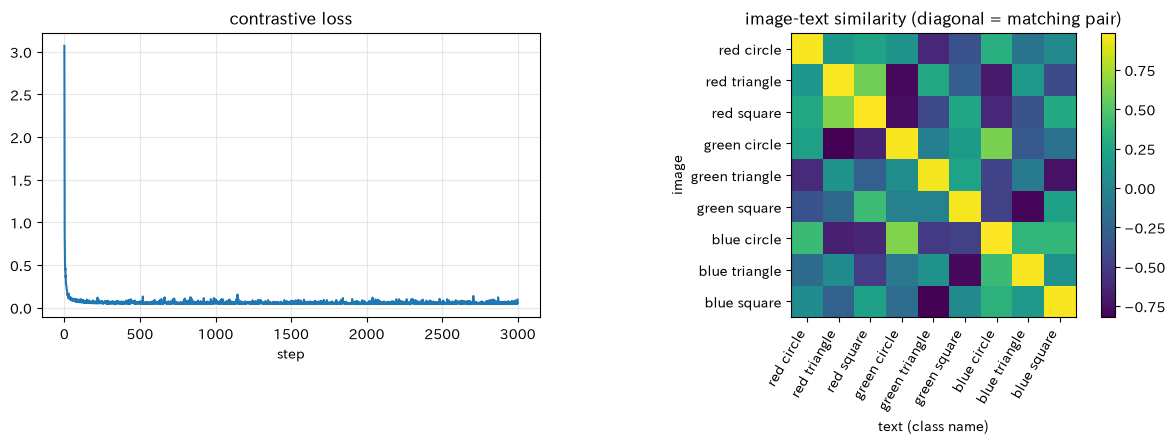

In [9]:
COLORS, SHAPES = ['red', 'green', 'blue'], ['circle', 'triangle', 'square']
COMBOS = [(c, s) for c in range(3) for s in range(3)]                    # 9 種類．(色, 形) の番号の組
# 色：0=赤, 1=緑, 2=青／形：0=丸, 1=三角, 2=四角．例：(0, 2) は赤い四角
HELD_OUT = [(0, 2), (2, 0)]                                              # 赤い四角，青い丸：学習に使わない
TRAIN = [cs for cs in COMBOS if cs not in HELD_OUT]

def attr(c, s):
    a = np.zeros(6); a[c] = 1; a[3 + s] = 1                              # [赤, 緑, 青, 丸, 三角, 四角] の 0/1 の表
    return a

r0 = np.random.default_rng(3)
A_img = r0.normal(size=(20, 6))                                          # 属性 → 画像を作る固定の規則（符号化器には教えない）
B_txt = r0.normal(size=(12, 6))                                          # 属性 → 文を作る固定の規則（符号化器には教えない）

def make_images(combos, r, noise=0.5):
    return np.stack([A_img @ attr(c, s) for c, s in combos]) + noise * r.normal(size=(len(combos), 20))

def make_texts(combos):
    return np.stack([B_txt @ attr(c, s) for c, s in combos])

def train_clip(train_combos, steps=3000, d_out=8, lr=0.2, seed=0):
    r = np.random.default_rng(seed)
    Wi = r.normal(size=(20, d_out)) * 0.1                                # 画像符号化器
    Wt = r.normal(size=(12, d_out)) * 0.1                                # テキスト符号化器
    T = make_texts(train_combos)
    hist = []
    for t in range(steps):
        Xi = make_images(train_combos, r)                                # 学習用の対のバッチ（画像は毎回ノイズが違う）
        (Zi, ni), (Zt, nt) = normalize(Xi @ Wi), normalize(T @ Wt)
        loss, gZi, gZt, _ = info_nce(Zi, Zt, tau=0.2)
        gUi = (gZi - Zi * np.sum(Zi * gZi, axis=1, keepdims=True)) / ni
        gUt = (gZt - Zt * np.sum(Zt * gZt, axis=1, keepdims=True)) / nt
        Wi -= lr * Xi.T @ gUi; Wt -= lr * T.T @ gUt
        hist.append(loss)
    return Wi, Wt, np.array(hist)

Wi, Wt, hist = train_clip(TRAIN)

# ---- ゼロショット分類：9 種類すべてのクラス名を文にして，画像と比べる
r = np.random.default_rng(42)
Zt_all, _ = normalize(make_texts(COMBOS) @ Wt)                            # クラス名の文の埋め込み（9×d）
labels = np.repeat(np.arange(9), 100)
Zi_all, _ = normalize(make_images([COMBOS[k] for k in labels], r) @ Wi)   # テスト画像 900 枚の埋め込み
S = Zi_all @ Zt_all.T                                                     # 画像×文の類似度
pred = S.argmax(axis=1)
held = np.isin(labels, [COMBOS.index(cs) for cs in HELD_OUT])
print(f"ゼロショット正解率：学習で見た 7 種類 {np.mean(pred[~held] == labels[~held]):.3f}，"
      f"一度も見ていない 2 種類 {np.mean(pred[held] == labels[held]):.3f}（でたらめに答えた場合は {1 / 9:.3f}）")

names9 = [f"{COLORS[c]} {SHAPES[s]}" for c, s in COMBOS]
Smean = np.stack([S[labels == k].mean(axis=0) for k in range(9)])        # クラスごとの平均類似度
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(hist); ax[0].set_title('contrastive loss'); ax[0].set_xlabel('step'); ax[0].grid(alpha=0.3)
im = ax[1].imshow(Smean, cmap='viridis'); fig.colorbar(im, ax=ax[1])
ax[1].set_xticks(range(9)); ax[1].set_xticklabels(names9, rotation=60, ha='right'); ax[1].set_yticks(range(9)); ax[1].set_yticklabels(names9)
ax[1].set_xlabel('text (class name)'); ax[1].set_ylabel('image'); ax[1].set_title('image-text similarity (diagonal = matching pair)')
plt.tight_layout(); plt.show()

    **読み取り**
    - 類似度行列の**対角成分**（対応する画像と文）が明るい．講義の図と同じ．
    - 分類器は 1 つも学習していない．クラス名の文を並べて，最も近いものを選んだだけ．
    - 学習で一度も見ていない組合せ（赤い四角，青い丸）も当たるのは，「赤」は赤い丸・赤い三角から，「四角」は緑や青の四角から学習済みで，文の側でも画像の側でもそれが組み合わさるから．

    **やってみよう 5-1（CLIP の限界，講義）**　学習に**一度も出てこない属性**はゼロショットでも認識できない．
除く組合せを「四角すべて」にして学習し直すと，四角の正解率はどうなるか．**先に予想を書く．**事前学習データの分布から外れた領域で性能が落ちることに対応する．

In [10]:
# (色, 形) の組で指定する．例：赤をすべて除くなら [(0, 0), (0, 1), (0, 2)]
held_out2 = [(0, 2), (1, 2), (2, 2)]                     # 四角をすべて除く  TODO: 他の除き方も試す
train2 = [cs for cs in COMBOS if cs not in held_out2]
Wi2, Wt2, _ = train_clip(train2)
r = np.random.default_rng(42)
Zt2, _ = normalize(make_texts(COMBOS) @ Wt2)
Zi2, _ = normalize(make_images([COMBOS[k] for k in labels], r) @ Wi2)
pred2 = (Zi2 @ Zt2.T).argmax(axis=1)
held2 = np.isin(labels, [COMBOS.index(cs) for cs in held_out2])
print(f"学習で見た {9 - len(held_out2)} 種類 {np.mean(pred2[~held2] == labels[~held2]):.3f}，"
      f"見ていない {len(held_out2)} 種類 {np.mean(pred2[held2] == labels[held2]):.3f}")
# 解答：四角の正解率は大きく落ちる．「四角」という概念を画像でも文でも一度も見ていないので，両者を対応づけられない．

学習で見た 6 種類 1.000，見ていない 3 種類 0.000


## §6（任意）PyTorch で対照損失を書く（テキスト付録B）

§3・§5 の `info_nce` は，PyTorch では「類似度行列をロジットとし，正解ラベルを $0,1,\dots,N-1$（対角）とする交差エントロピー」の 3 行で書ける．

In [11]:
try:
    import torch
    import torch.nn.functional as F

    def clip_loss(z_img, z_txt, tau=0.2):
        z_img, z_txt = F.normalize(z_img, dim=1), F.normalize(z_txt, dim=1)
        logits = z_img @ z_txt.T / tau                       # N×N の類似度行列
        target = torch.arange(len(logits))                   # 正解は対角
        return (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target)) / 2

    za = torch.tensor(make_images(TRAIN, np.random.default_rng(0)) @ Wi, dtype=torch.float32)
    zb = torch.tensor(make_texts(TRAIN) @ Wt, dtype=torch.float32)
    print("PyTorch の損失 =", clip_loss(za, zb).item())
    Za_, _ = normalize(za.numpy()); Zb_, _ = normalize(zb.numpy())
    print("NumPy の損失   =", info_nce(Za_, Zb_, tau=0.2)[0])   # 一致する
except ImportError:
    print("PyTorch が見つからないので，この節は読み飛ばす．")

PyTorch の損失 = 0.05093624070286751
NumPy の損失   = 0.050936237


## §7 補足：学習済み表現の埋め込み空間：DINOv2 と CLIP で実画像の類似検索

§1 では小さな埋め込み空間で類似検索をした．ここでは本物の事前学習済み表現で，実画像（COCO の写真 12 枚）を埋め込み，クエリ画像に近い画像を探す．比べるのは 2 系統：**DINOv2**（画像だけの自己教師あり学習．`facebook/dinov2-small`）と **CLIP**（画像とテキストの対照学習．`openai/clip-vit-base-patch32`）．どちらも「似た画像が近くに来る」が，何を「似ている」とみなすかが違う．

```{admonition} 補足節について
:class: note
ここから先は，講義で扱った構造を **実際に学習された本物のモデル** と **実画像** で動かす補足である．[torchvision](https://pytorch.org/vision/) や [Hugging Face Transformers](https://huggingface.co/docs/transformers) から学習済みモデルを取得する（初回はダウンロードに数分かかる．Colab ではインストール不要）．
手元で動かすには `pip install transformers datasets` と，インターネット接続が要る．入っていない環境では，このあとのセルは何もしない．
```

In [12]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TQDM_DISABLE"] = "1"   # ダウンロードの進捗表示を出さない
warnings.filterwarnings("ignore")
try:
    import torch
    import transformers
    import requests
    from PIL import Image
    transformers.logging.set_verbosity_error()
    HAS_HF = True
except ImportError:
    HAS_HF = False
    print("PyTorch か transformers が見つからないので，補足節のセルは何もしない（読み飛ばす）．")

def fetch_image(name):
    """COCO val2017 の画像を取得して PIL の画像で返す（ダウンロードは初回だけ．images/ に保存）"""
    import os
    os.makedirs("images", exist_ok=True)
    path = os.path.join("images", name)
    if not os.path.exists(path):
        r = requests.get("http://images.cocodataset.org/val2017/" + name, timeout=60)
        r.raise_for_status()
        open(path, "wb").write(r.content)
    return Image.open(path).convert("RGB")

COCO_IMAGES = {   # ファイル名: 内容
    "000000039769.jpg": "2 匹の猫とリモコン", "000000000285.jpg": "クマ", "000000000724.jpg": "一時停止の標識",
    "000000000776.jpg": "テディベア", "000000000785.jpg": "スキーヤー", "000000000802.jpg": "台所",
    "000000001268.jpg": "川辺と白鳥", "000000000632.jpg": "寝室",
}

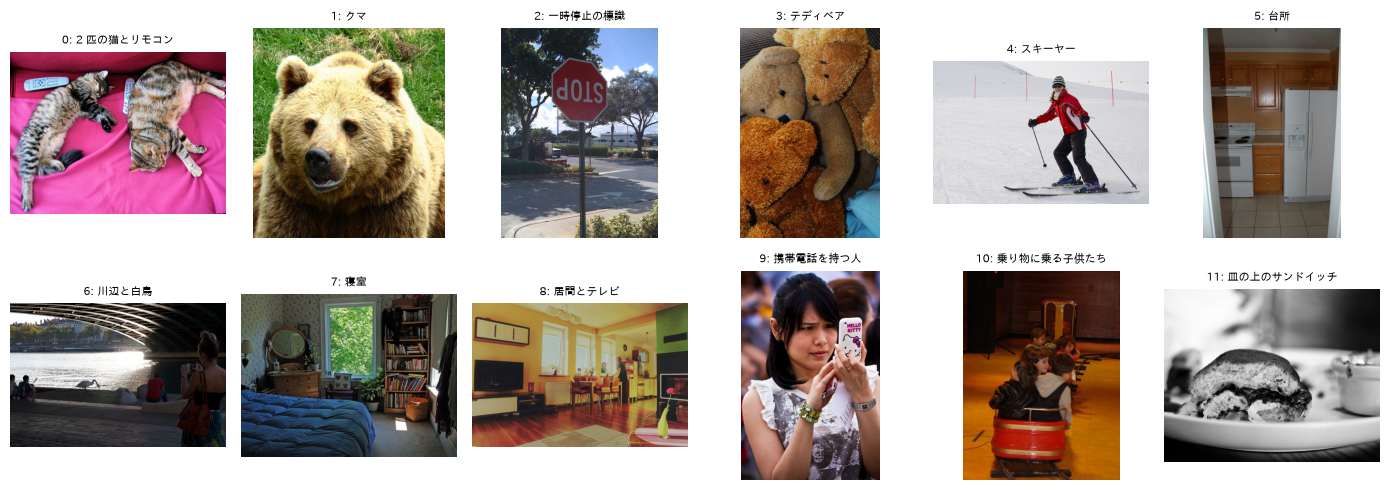

In [13]:
if HAS_HF:
    from transformers import AutoImageProcessor, AutoModel, CLIPModel, CLIPProcessor
    extra = {"000000000139.jpg": "居間とテレビ", "000000001296.jpg": "携帯電話を持つ人", "000000001353.jpg": "乗り物に乗る子供たち", "000000001425.jpg": "皿の上のサンドイッチ"}
    names = list(COCO_IMAGES) + list(extra)
    captions = {**COCO_IMAGES, **extra}
    images = [fetch_image(n) for n in names]
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for k, (ax, img) in enumerate(zip(axes.flat, images)):
        ax.imshow(img); ax.axis("off"); ax.set_title(f"{k}: {captions[names[k]]}", fontsize=8)
    plt.tight_layout(); plt.show()

In [14]:
# 補助コード：2 つのモデルで画像埋め込みを計算し，長さ 1 に正規化する
if HAS_HF:
    dproc = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
    dino = AutoModel.from_pretrained("facebook/dinov2-small").eval()
    cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
    with torch.no_grad():
        Z_dino = dino(**dproc(images=images, return_tensors="pt")).pooler_output            # クラストークンの出力 (12, 384)
        Z_clip = clip(**cproc(text=["a photo"], images=images, return_tensors="pt", padding=True)).image_embeds   # (12, 512)
    Z_dino = Z_dino / Z_dino.norm(dim=1, keepdim=True); Z_clip = Z_clip / Z_clip.norm(dim=1, keepdim=True)
    print("DINOv2 の埋め込み", tuple(Z_dino.shape), " CLIP の埋め込み", tuple(Z_clip.shape))

DINOv2 の埋め込み (12, 384)  CLIP の埋め込み (12, 512)


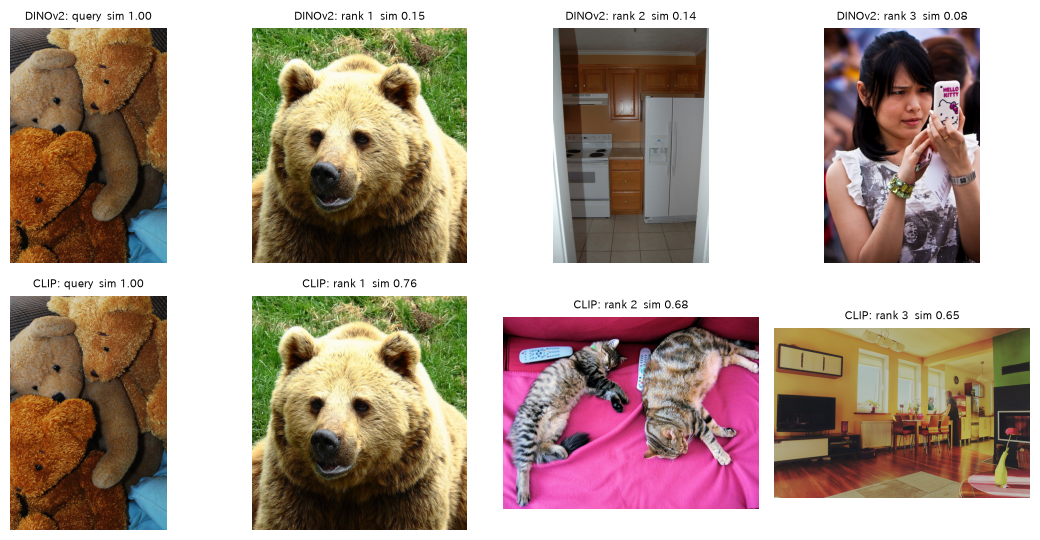

In [15]:
if HAS_HF:
    query = 3   # TODO: 0〜11 で変える（3 はテディベア）
    fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
    for row, (name, Z) in enumerate((("DINOv2", Z_dino), ("CLIP", Z_clip))):
        sims = Z @ Z[query]                                         # クエリとのコサイン類似度（§1 と同じ）
        order = sims.argsort(descending=True)[:4]                   # 先頭はクエリ自身
        for col, j in enumerate(order):
            ax = axes[row, col]; ax.imshow(images[int(j)]); ax.axis("off")
            ax.set_title(f"{name}: {'query' if col == 0 else f'rank {col}'}  sim {float(sims[j]):.2f}", fontsize=8)
    plt.tight_layout(); plt.show()

読み方：クエリに近い順に並べた．クマとテディベアは見た目も意味も近いので，どちらのモデルでも互いに最も近い．それ以外では 2 つのモデルの「近さ」は違う．DINOv2 は画像だけから学習しているので色・質感・構図が近いものを，CLIP は説明文と一緒に学習しているので「何が写っているか」が近いものを上位に出しやすい．12 枚しかないので 1 枚だけのカテゴリ（標識，スキーヤー，白鳥 …）は，どちらかというと構図や色の似た画像と結びつく．どちらが「正しい」かは用途で決まる（第12回：見た目の類似検索か，言語で指定する検索か）．

12 枚全体の類似度行列を比べる．対角が 1．CLIP では部屋の写真（5 台所，7 寝室，8 居間）が互いに近い．

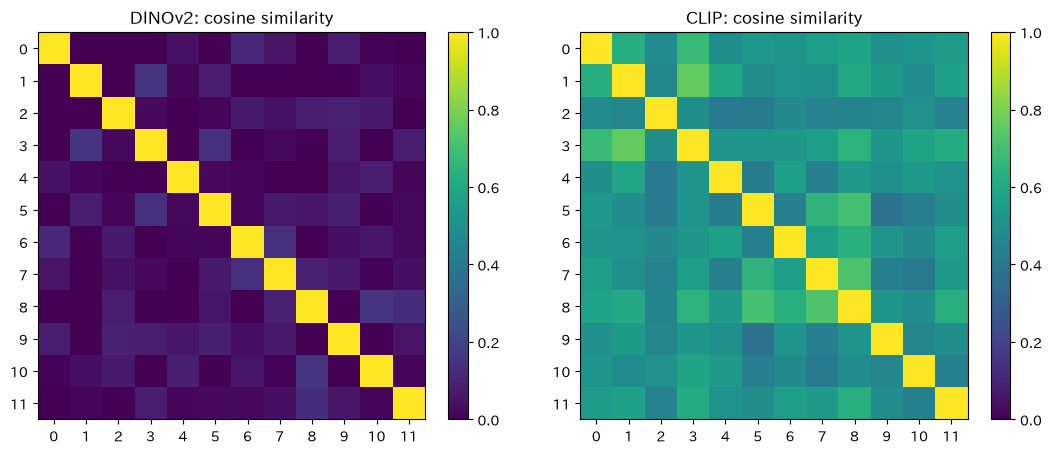

DINOv2 で各画像に最も近い画像: [(0, 6), (1, 3), (2, 9), (3, 1), (4, 10), (5, 3), (6, 7), (7, 6), (8, 10), (9, 2), (10, 8), (11, 8)]
CLIP で各画像に最も近い画像: [(0, 3), (1, 3), (2, 10), (3, 1), (4, 1), (5, 8), (6, 8), (7, 8), (8, 7), (9, 1), (10, 3), (11, 8)]


In [16]:
if HAS_HF:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, (name, Z) in zip(axes, (("DINOv2", Z_dino), ("CLIP", Z_clip))):
        S = (Z @ Z.T).numpy()
        im = ax.imshow(S, cmap="viridis", vmin=0, vmax=1); ax.set_title(f"{name}: cosine similarity"); ax.set_xticks(range(12)); ax.set_yticks(range(12))
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.show()
    # 対角を除いた「最も近い相手」
    for name, Z in (("DINOv2", Z_dino), ("CLIP", Z_clip)):
        S = Z @ Z.T; S.fill_diagonal_(-1)
        print(f"{name} で各画像に最も近い画像:", [(k, int(S[k].argmax())) for k in range(12)])

読み方：CLIP では部屋の写真どうし（5・7・8）が互いに最も近い相手になる．DINOv2 では必ずしもそうならず，見た目の近さで相手が決まる．どちらの表現も，ラベルを 1 つも使わずに（DINOv2）あるいはラベルの代わりに説明文を使って（CLIP）学習されている．それでも「近さ」に意味のある空間ができている．§3〜§5 で小さく作った対照学習の仕組みが，大規模データで学習されるとこうなる．

**やってみよう 7-1**　`query` を 11（サンドイッチ）や 4（スキーヤー）にして，2 つのモデルの上位 3 枚を比べる．食べ物や雪景色のように 1 枚しかないカテゴリでは，何が「近い」とされるか．